# 06 · El modelo Luna contra Marte: atributos, reglas y métricas

<a href="https://colab.research.google.com/github/Niettzche/spaceapps-2026/blob/main/ciencia_datos/06_modelo_luna_marte.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

Notebook de estudio del modelo que usamos para juzgar los cráteres de la Tierra. Reproduce **el mismo modelo** de
`03_etiquetas_por_fuentes.ipynb` (sección 4), explicado paso a paso.

**La idea.** Las etiquetas de la Tierra son pocas y ruidosas. Así que entrenamos **solo con datos limpios** (cráteres de la Luna y de Marte medidos con el mismo detector)
y después le pasamos los cráteres de la Tierra **como invitados**: ¿se parecen más a la Luna o a Marte?, ¿caen dentro del rango de formas de los dos?

**Dos modelos con los mismos datos**
- **Regresión logística** (el modelo oficial, el del 78 %): da una probabilidad P(Luna) y sus coeficientes dicen hacia dónde empuja cada atributo.
- **Árbol de decisión** de profundidad 3: sus reglas se leen como preguntas de sí o no.

**Contenido:** 1. atributos · 2. cómo se ven · 3. validación · 4. métricas · 5. matrices de confusión · 6. coeficientes y árbol · 7. sitios de Marte nunca vistos ·
8. la Tierra como invitada · 9. resumen. Las cifras del resumen se calculan en el notebook; no hay números escritos a mano.

In [1]:
# Carga de datos: funciona local (repo clonado) y en Colab (repo privado: token de GitHub en el secreto GITHUB_TOKEN)
import subprocess
from pathlib import Path
REPO, RUTA = "Niettzche/spaceapps-2026", "ciencia_datos/datos"
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / RUTA / "hoyas_referencia.csv").exists()), None)
if RAIZ is None:
    try:
        from google.colab import userdata
        url = f"https://{userdata.get('GITHUB_TOKEN')}@github.com/{REPO}.git"
    except Exception:
        url = f"https://github.com/{REPO}.git"
    subprocess.run(["git", "clone", "--depth", "1", url, "/content/spaceapps-2026"], check=True)
    RAIZ = Path("/content/spaceapps-2026")
DATOS = RAIZ / RUTA
print("Datos en", DATOS)

Datos en ciencia_datos/datos


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay, precision_recall_fscore_support
from sklearn.covariance import MinCovDet
from sklearn.inspection import permutation_importance

CLASES = ["Luna", "Marte"]
COLORES = {"Luna": "#8a8f98", "Marte": "#b5532f", "Tierra": "#1f6f78", "mina": "#c7921a"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 150)

ref = pd.read_csv(DATOS / "hoyas_referencia.csv")
mx = pd.read_csv(DATOS / "crateres_mexico.csv")
imp = pd.read_csv(DATOS / "impactos_tierra.csv")
print("Depresiones de Luna + Marte:", len(ref), "| detecciones de México:", len(mx), "| impactos de la Tierra:", len(imp))

Depresiones de Luna + Marte: 7717 | detecciones de México: 668 | impactos de la Tierra: 10


## 1. Los atributos

De cada cráter el detector saca varias medidas. Este modelo usa **3**, medidas igual en la Luna y en Marte (mismo código, píxel de 200 m):

| Atributo | Qué mide | En palabras | Cómo se calcula |
|---|---|---|---|
| `log_diam` | tamaño | qué tan ancho es | log10 del diámetro en km (va de 0.6 a 10 km; el log evita que los grandes dominen) |
| `prof_diam` | **d/D** | qué tan *hondo* es para su tamaño | profundidad (m) / diámetro (m). Un cráter lunar fresco ronda 0.2; uno viejo o relleno, mucho menos |
| `borde_rel` | borde / diámetro | qué tanto se levanta el borde sobre el terreno de alrededor | altura del borde (m) / diámetro (m) |

**Por qué solo 3.** El modelo de tres clases del notebook 01 usaba además `relleno` y `aspecto`, pero el notebook 02 mostró que, en cráteres de menos de
~20 píxeles (la mitad), esos dos son sobre todo **ruido de la cuadrícula**, no forma. Tamaño, d/D y borde son lo que de verdad describe un cráter.
La elevación absoluta se descarta porque cada cuerpo tiene su propio "nivel del mar" y el modelo haría trampa con ella.

**Qué cráteres entran.** Los que pasan el filtro de cráter (0.6–10 km, ≥ 20 m de hondo, circularidad ≥ 0.6). De Marte se usan 6 sitios con cráteres suficientes;
Elysium y Utopia se excluyen (14 y 9 cráteres, llanuras muy lisas donde el modelo de elevación puede ser solo MOLA, de baja resolución).

In [3]:
FD = ["log_diam", "prof_diam", "borde_rel"]
NOMBRES = {"log_diam": "log10 diámetro (km)", "prof_diam": "profundidad / diámetro", "borde_rel": "borde / diámetro"}

def preparar(d):
    d = d.copy(); d["log_diam"] = np.log10(d.diam_km); d["borde_rel"] = d.borde_m / (d.diam_km * 1000); return d

r = preparar(ref[ref.crater])
r["grupo"] = r.cuerpo + "|" + r.sitio + "|" + (r.i // 250).astype(int).astype(str) + "_" + (r.j // 250).astype(int).astype(str)
lm = r[~r.sitio.str.contains("Elysium|Utopia")].reset_index(drop=True)
X, y, g = lm[FD].to_numpy(float), lm.cuerpo.to_numpy(object), lm.grupo.to_numpy(object)
print(lm.groupby(["cuerpo", "sitio"]).size().to_string())
print("\nTotal:", lm.cuerpo.value_counts().to_dict(), "| bloques espaciales:", lm.groupby("cuerpo").grupo.nunique().to_dict())

cuerpo  sitio                  
Luna    Anillo 80-85°S             3232
        Polo sur (85-90°S)         1056
Marte   Chryse (Viking 1)            23
        Cráter Gale                  90
        Cráter Jezero               104
        Gusev (Spirit)              101
        Meridiani (Opportunity)     165
        Oxia Planum                  90

Total: {'Luna': 4288, 'Marte': 573} | bloques espaciales: {'Luna': 140, 'Marte': 24}


## 2. Cómo se ven los atributos en la Luna y en Marte

Cada caja va del percentil 25 al 75; la raya es la mediana. Si las cajas se enciman mucho, ese atributo solo no separa los cuerpos.

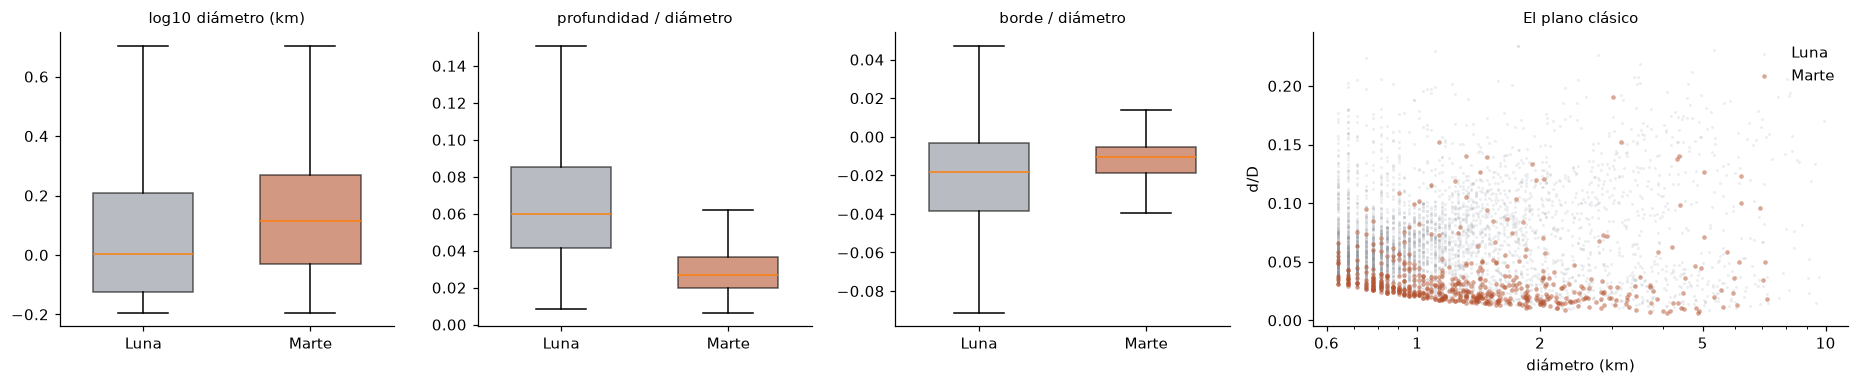

Medianas:
        log_diam  prof_diam  borde_rel
cuerpo                                
Luna       0.004      0.060     -0.018
Marte      0.113      0.027     -0.010


In [4]:
fig, axs = plt.subplots(1, 4, figsize=(17, 3.6), gridspec_kw={"width_ratios": [1, 1, 1, 1.6]})
for ax, f in zip(axs, FD):
    bp = ax.boxplot([lm.loc[lm.cuerpo == c, f] for c in CLASES], tick_labels=CLASES, patch_artist=True, showfliers=False, widths=.6)
    for p, c in zip(bp["boxes"], CLASES): p.set_facecolor(COLORES[c]); p.set_alpha(.6)
    ax.set_title(NOMBRES[f], fontsize=10)
for c, s, a in [("Luna", 4, .15), ("Marte", 9, .5)]:
    d = lm[lm.cuerpo == c]; axs[3].scatter(d.diam_km, d.prof_diam, s=s, alpha=a, color=COLORES[c], lw=0, label=c)
axs[3].set_xscale("log"); axs[3].set_xticks([0.6, 1, 2, 5, 10]); axs[3].set_xticklabels(["0.6", "1", "2", "5", "10"])
axs[3].set_xlabel("diámetro (km)"); axs[3].set_ylabel("d/D"); axs[3].legend(frameon=False); axs[3].set_title("El plano clásico", fontsize=10)
fig.tight_layout(); plt.show()
print("Medianas:"); print(lm.groupby("cuerpo")[FD].median().round(3).to_string())

**Cómo leerlo.** Compara las medianas de arriba: si d/D es más bajo en Marte, sus cráteres son **más planos para su tamaño**
(en Marte hay polvo, viento y, en el pasado, agua, que rellenan los cráteres). La sección 6 confirma con números qué atributo separa más.

## 3. Cómo medimos: validación por grupos espaciales

- Partimos los datos en 5 pliegues; se entrena con 4 y se califica el que queda fuera. Así **cada cráter lo califica un modelo que no lo vio**.
- Los pliegues se arman por **bloques de ~50 km**: cráteres vecinos (casi idénticos) caen siempre juntos. Si se partiera al azar, el modelo vería
  al "vecino gemelo" y la exactitud saldría inflada.
- **Pesos por clase** (`class_weight="balanced"`): hay muchos más cráteres lunares que marcianos. Sin pesos, el modelo diría "Luna" casi siempre.
- Repetimos todo con **20 semillas** (formas distintas de repartir los bloques) y reportamos promedio y rango: así se ve qué tan estable es la cifra.

In [5]:
logistica = lambda: make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=3000))
arbol_f = lambda: DecisionTreeClassifier(max_depth=3, min_samples_leaf=3, class_weight="balanced", random_state=0)
MODELOS = {"Regresión logística": logistica, "Árbol profundidad 3": arbol_f}

def fuera_de_pliegue(hacer, semilla):
    pred = np.empty(len(y), object)
    for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=semilla).split(X, y, g):
        pred[te] = hacer().fit(X[tr], y[tr]).predict(X[te])
    return pred

filas, PRED0 = [], {}
for nombre, hacer in MODELOS.items():
    for s in range(20):
        p = fuera_de_pliegue(hacer, s)
        if s == 0: PRED0[nombre] = p
        filas.append({"modelo": nombre, "exactitud normal": accuracy_score(y, p), "exactitud balanceada": balanced_accuracy_score(y, p),
                      "acierto Luna": (p[y == "Luna"] == "Luna").mean(), "acierto Marte": (p[y == "Marte"] == "Marte").mean()})
rep = pd.DataFrame(filas)
print("listo:", len(rep), "evaluaciones")

listo: 40 evaluaciones


## 4. Métricas

- **Exactitud normal**: aciertos / total. Engaña con clases desbalanceadas: decir siempre "Luna" acierta muchísimo aquí (ver la última fila).
- **Exactitud balanceada**: el promedio del acierto **de cada clase**. Decir siempre "Luna" da 50 % (100 % en Luna, 0 % en Marte). Es nuestra métrica principal.
- **Acierto por clase (exhaustividad o recall)**: de los cráteres que *son* de la Luna, cuántos dijo Luna; igual para Marte.
- **Precisión**: de los que el modelo *dijo* Marte, cuántos son de Marte. **F1**: balance entre precisión y recall.

In [6]:
tabla = rep.groupby("modelo").agg(["mean", "min", "max"]) * 100
fmt = pd.DataFrame({c: tabla[c].apply(lambda r: f"{r['mean']:.0f} % ({r['min']:.0f}–{r['max']:.0f})", axis=1) for c in rep.columns[1:]})
siempre_luna = np.full(len(y), "Luna", dtype=object)
fmt.loc["Decir siempre 'Luna'"] = [f"{accuracy_score(y, siempre_luna):.0%}", f"{balanced_accuracy_score(y, siempre_luna):.0%}", "100 %", "0 %"]
print("Promedio de 20 repeticiones (mínimo–máximo):"); print(fmt.to_string())

Promedio de 20 repeticiones (mínimo–máximo):
                     exactitud normal exactitud balanceada  acierto Luna acierto Marte
modelo                                                                                
Regresión logística      74 % (74–74)         78 % (77–78)  73 % (72–73)  82 % (81–83)
Árbol profundidad 3      80 % (79–82)         78 % (77–79)  81 % (80–83)  75 % (72–77)
Decir siempre 'Luna'              88%                  50%         100 %           0 %


In [7]:
print("Por clase, semilla 0:")
for nombre, p in PRED0.items():
    pr, rc, f1, n = precision_recall_fscore_support(y, p, labels=CLASES, zero_division=0)
    t = pd.DataFrame({"casos": n, "precisión": pr, "recall": rc, "F1": f1}, index=CLASES)
    for c in ["precisión", "recall", "F1"]: t[c] = (t[c] * 100).round(0).astype(int).astype(str) + " %"
    print(f"\n{nombre}"); print(t.to_string())

Por clase, semilla 0:

Regresión logística
       casos precisión recall    F1
Luna    4288      97 %   73 %  83 %
Marte    573      29 %   82 %  43 %

Árbol profundidad 3
       casos precisión recall    F1
Luna    4288      96 %   80 %  88 %
Marte    573      34 %   76 %  47 %


**Ojo con la precisión de Marte.** Sale más baja que su recall porque hay muchos más lunares que marcianos: aunque solo una fracción de los lunares
se confunda con Marte, son muchos cráteres comparados con los de Marte. Es el precio de darle a Marte el mismo peso que a la Luna.

## 5. Matrices de confusión

Filas = **lo que de verdad es**; columnas = **lo que dijo el modelo** (semilla 0, fuera de pliegue). La diagonal son aciertos.
Arriba en conteos; abajo en porcentaje de cada fila (la diagonal es el recall de cada clase).

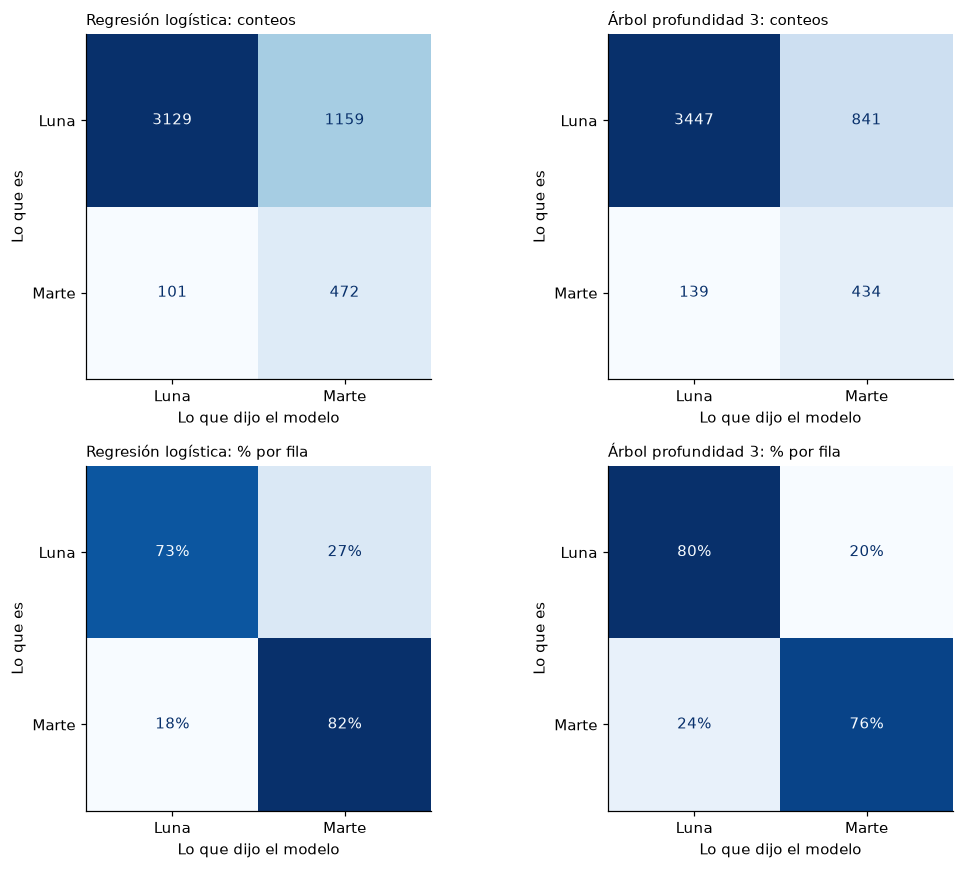

In [8]:
fig, axs = plt.subplots(2, 2, figsize=(10, 8))
for j, (nombre, p) in enumerate(PRED0.items()):
    ConfusionMatrixDisplay(confusion_matrix(y, p, labels=CLASES), display_labels=CLASES).plot(ax=axs[0, j], cmap="Blues", values_format="d", colorbar=False)
    ConfusionMatrixDisplay(confusion_matrix(y, p, labels=CLASES, normalize="true"), display_labels=CLASES).plot(ax=axs[1, j], cmap="Blues", values_format=".0%", colorbar=False)
    axs[0, j].set_title(f"{nombre}: conteos", loc="left", fontsize=10); axs[1, j].set_title(f"{nombre}: % por fila", loc="left", fontsize=10)
for a in axs.ravel(): a.set_xlabel("Lo que dijo el modelo"); a.set_ylabel("Lo que es")
fig.tight_layout(); plt.show()

## 6. Por dentro: coeficientes de la logística y reglas del árbol

### Regresión logística
Con los atributos estandarizados (en unidades de desviación estándar), cada coeficiente dice **hacia dónde empuja** ese atributo.
Positivo = empuja hacia **Marte**; negativo = hacia **Luna** (scikit-learn toma como clase positiva la segunda en orden alfabético: Marte).
El tamaño dice cuánto. Se entrena con todos los datos (las métricas ya se midieron fuera de pliegue).

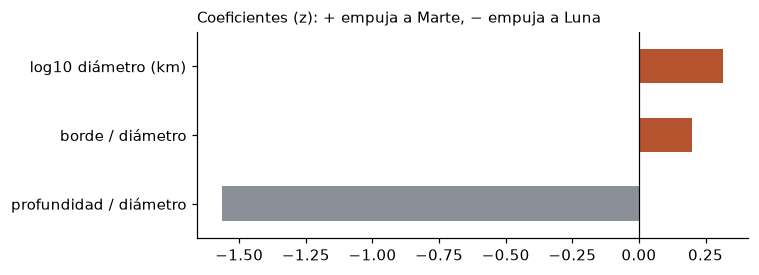

profundidad / diámetro   -1.56
borde / diámetro          0.20
log10 diámetro (km)       0.32



Importancia por permutación (cuánto baja la exactitud balanceada al revolver cada atributo):
profundidad / diámetro    0.253
log10 diámetro (km)       0.023
borde / diámetro          0.001


In [9]:
modelo_lm = logistica().fit(X, y)
assert list(modelo_lm.classes_) == CLASES
coef = pd.Series(modelo_lm[-1].coef_[0], index=[NOMBRES[f] for f in FD]).sort_values()
ax = coef.plot.barh(figsize=(7, 2.6), color=[COLORES["Marte"] if v > 0 else COLORES["Luna"] for v in coef])
ax.axvline(0, color="k", lw=.8); ax.set_title("Coeficientes (z): + empuja a Marte, − empuja a Luna", loc="left", fontsize=10); plt.tight_layout(); plt.show()
print(coef.round(2).to_string())
perm = permutation_importance(modelo_lm, X, y, scoring="balanced_accuracy", n_repeats=20, random_state=0)
importancia = pd.Series(perm.importances_mean, index=[NOMBRES[f] for f in FD]).sort_values(ascending=False)
print("\nImportancia por permutación (cuánto baja la exactitud balanceada al revolver cada atributo):")
print(importancia.round(3).to_string())

### Árbol de decisión
Un árbol hace **preguntas de sí o no** ("¿d/D ≤ 0.05?"): si se cumple vas a la **izquierda**, si no a la **derecha**, hasta llegar a una **hoja**.
En cada nodo: `samples` = % de los datos que llega ahí; `value` = proporción **ponderada** de Luna y Marte; `class` = la que gana.
Color más intenso = hoja más segura.

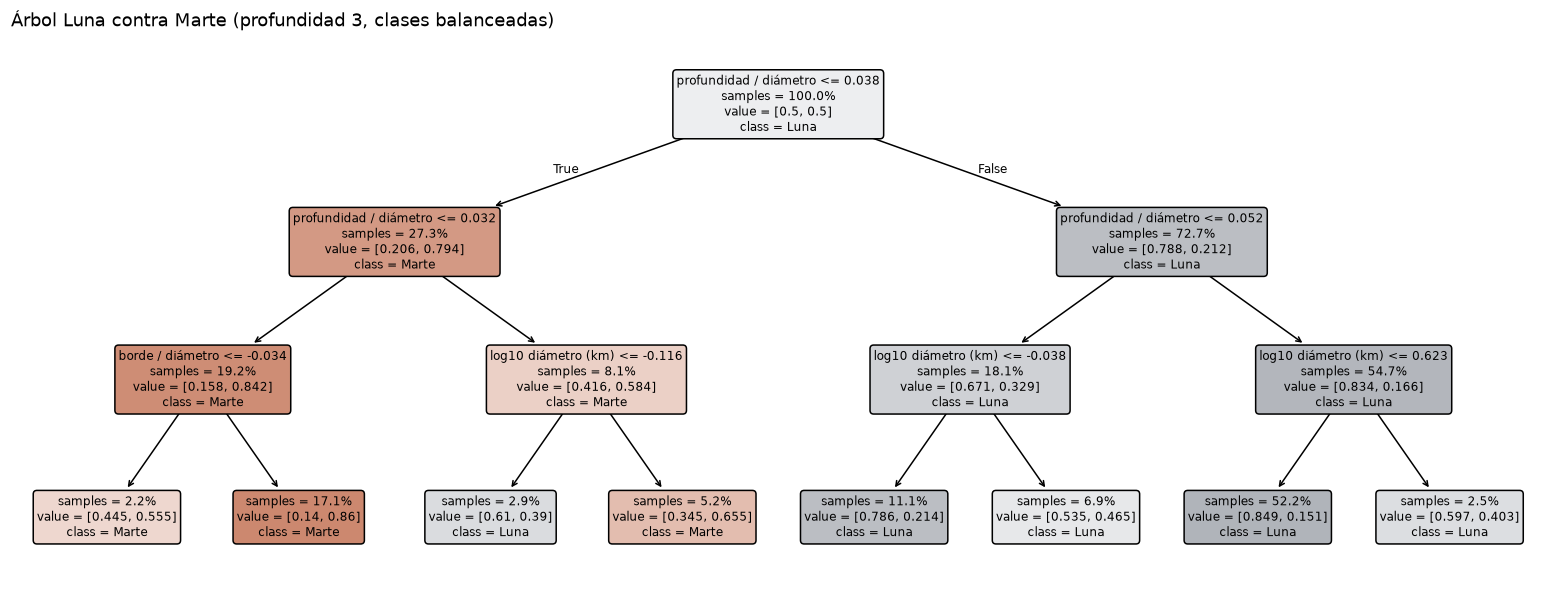

|--- profundidad / diámetro <= 0.038
|   |--- profundidad / diámetro <= 0.032
|   |   |--- borde / diámetro <= -0.034
|   |   |   |--- class: Marte
|   |   |--- borde / diámetro >  -0.034
|   |   |   |--- class: Marte
|   |--- profundidad / diámetro >  0.032
|   |   |--- log10 diámetro (km) <= -0.116
|   |   |   |--- class: Luna
|   |   |--- log10 diámetro (km) >  -0.116
|   |   |   |--- class: Marte
|--- profundidad / diámetro >  0.038
|   |--- profundidad / diámetro <= 0.052
|   |   |--- log10 diámetro (km) <= -0.038
|   |   |   |--- class: Luna
|   |   |--- log10 diámetro (km) >  -0.038
|   |   |   |--- class: Luna
|   |--- profundidad / diámetro >  0.052
|   |   |--- log10 diámetro (km) <= 0.623
|   |   |   |--- class: Luna
|   |   |--- log10 diámetro (km) >  0.623
|   |   |   |--- class: Luna



In [10]:
arbol = arbol_f().fit(X, y)
fig, ax = plt.subplots(figsize=(18, 6.5))
anots = plot_tree(arbol, feature_names=[NOMBRES[f] for f in FD], class_names=list(arbol.classes_), filled=True, rounded=True,
                  impurity=False, proportion=True, fontsize=8, ax=ax)
for a in anots:
    t = a.get_text()
    if "class = " in t and a.get_bbox_patch() is not None:
        c = t.split("class = ")[1].strip()
        v = [float(x) for x in t.split("value = [")[1].split("]")[0].split(",")]
        k = 0.15 + 0.75 * (max(v) - 0.5) / 0.5
        a.get_bbox_patch().set_facecolor(tuple(1 - k + k * ch for ch in to_rgba(COLORES[c])[:3]))
ax.set_title("Árbol Luna contra Marte (profundidad 3, clases balanceadas)", loc="left"); plt.show()
print(export_text(arbol, feature_names=[NOMBRES[f] for f in FD], decimals=3))

## 7. Prueba dura: sitios de Marte que el modelo nunca vio

Para ver si generaliza, entrenamos **sin un sitio de Marte entero** y lo calificamos solo en ese sitio. Se repite con cada sitio.
Si el modelo solo memorizara un sitio, aquí fallaría.

In [11]:
filas = []
for s in lm[lm.cuerpo == "Marte"].sitio.unique():
    tr, te = lm[lm.sitio != s], lm[lm.sitio == s]
    for nombre, hacer in MODELOS.items():
        m_ = hacer().fit(tr[FD].to_numpy(float), tr.cuerpo.to_numpy(object))
        filas.append({"sitio nunca visto": s, "cráteres": len(te), "modelo": nombre, "acierto": (m_.predict(te[FD].to_numpy(float)) == "Marte").mean()})
sitios = pd.DataFrame(filas).pivot_table(index=["sitio nunca visto", "cráteres"], columns="modelo", values="acierto")
print((sitios * 100).round(0).astype(int).astype(str).add(" %").to_string())

modelo                           Regresión logística Árbol profundidad 3
sitio nunca visto       cráteres                                        
Chryse (Viking 1)       23                      91 %                83 %
Cráter Gale             90                      70 %                58 %
Cráter Jezero           104                     82 %                73 %
Gusev (Spirit)          101                     75 %                68 %
Meridiani (Opportunity) 165                     92 %                85 %
Oxia Planum             90                      84 %                67 %


## 8. La Tierra como invitada

Ahora los cráteres de la Tierra. Para cada uno calculamos, con los modelos entrenados **solo con Luna y Marte**:

1. **P(Luna)**: la probabilidad de la logística de que sea lunar (1 − P(Luna) = marciano). También lo que diría el árbol.
2. **¿Dentro del 95 %?**: la **distancia de Mahalanobis** robusta a la nube de cráteres de Luna y Marte. Mide qué tan lejos está un punto del
   "centro" de la nube, tomando en cuenta su forma. Si cae dentro del 95 % de la nube, **en forma es un análogo plausible**; si cae fuera,
   la analogía se rompe por forma (por ejemplo, demasiado hondo).

Usamos los cráteres áridos de México (NDVI p90 < 0.35) y los cráteres de impacto de la Tierra que encuentra el detector.

In [12]:
esc = StandardScaler().fit(lm[FD]); mcd = MinCovDet(random_state=0).fit(esc.transform(lm[FD]))
corte = np.quantile(mcd.mahalanobis(esc.transform(lm[FD])), 0.95)

def invitar(d):
    d = preparar(d)
    d["P_Luna"] = modelo_lm.predict_proba(d[FD].to_numpy(float))[:, 0]
    d["arbol_dice"] = arbol.predict(d[FD].to_numpy(float))
    d["dentro_95"] = mcd.mahalanobis(esc.transform(d[FD])) <= corte
    return d

mxa = invitar(mx[mx.ndvi_p90 < 0.35])
im = invitar(imp[imp.detectado.astype(bool) & (imp.nombre != "Xiuyan")])
print(f"México árido: {len(mxa)} cráteres; dentro del 95 % de la nube Luna+Marte: {mxa.dentro_95.mean():.0%}")
print(mxa.groupby("tipo").agg(n=("P_Luna", "size"), P_Luna_media=("P_Luna", "mean"), dentro_95=("dentro_95", "mean")).round(2).to_string())
print(f"\nImpactos de la Tierra dentro de la nube: {int(im.dentro_95.sum())} de {len(im)}")
cols = ["nombre", "diam_km", "prof_diam", "P_Luna", "arbol_dice", "dentro_95"]
print("\nCon nombre:")
print(pd.concat([mxa[mxa.nombre.notna()][cols], im[cols]]).sort_values("P_Luna", ascending=False).round(3).to_string(index=False))

México árido: 47 cráteres; dentro del 95 % de la nube Luna+Marte: 89%
            n  P_Luna_media  dentro_95
tipo                                  
con_borde   4          0.81       0.75
mina       10          0.94       0.60
sin_borde  33          0.35       1.00

Impactos de la Tierra dentro de la nube: 8 de 8

Con nombre:
                    nombre  diam_km  prof_diam  P_Luna arbol_dice  dentro_95
    Real de Ángeles (Zac.)    0.930      0.289   1.000       Luna      False
          Hércules (Coah.)    0.814      0.257   1.000       Luna      False
          Hércules (Coah.)    0.903      0.214   0.999       Luna      False
          Sykes (Pinacate)    0.903      0.197   0.998       Luna      False
         Peñasquito (Zac.)    1.658      0.188   0.997       Luna      False
    El Elegante (Pinacate)    1.445      0.139   0.972       Luna       True
             Meteor Crater    1.058      0.126   0.958       Luna       True
       La Herradura (Son.)    1.777      0.120   0.942   

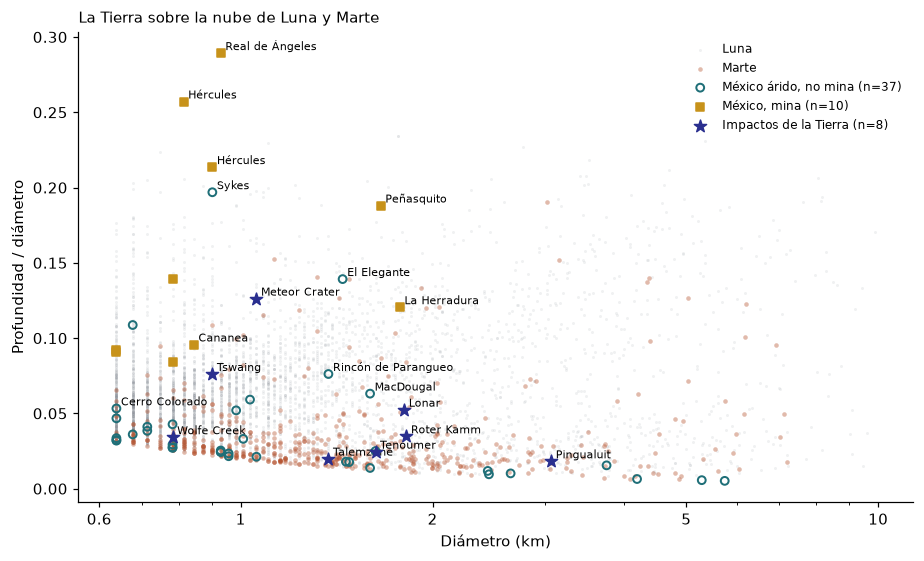

In [13]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
for c, s, a in [("Luna", 4, .12), ("Marte", 9, .4)]:
    d = lm[lm.cuerpo == c]; ax.scatter(d.diam_km, d.prof_diam, s=s, alpha=a, color=COLORES[c], lw=0, label=c)
nat, mina = mxa[mxa.tipo != "mina"], mxa[mxa.tipo == "mina"]
ax.scatter(nat.diam_km, nat.prof_diam, s=26, facecolors="none", edgecolors=COLORES["Tierra"], lw=1.3, label=f"México árido, no mina (n={len(nat)})", zorder=3)
ax.scatter(mina.diam_km, mina.prof_diam, s=28, marker="s", color=COLORES["mina"], label=f"México, mina (n={len(mina)})", zorder=3)
ax.scatter(im.diam_km, im.prof_diam, s=70, marker="*", color="#2a2f8f", label=f"Impactos de la Tierra (n={len(im)})", zorder=4)
for _, p in pd.concat([mxa[mxa.nombre.notna()], im]).iterrows():
    ax.annotate(str(p.nombre).split(" (")[0], (p.diam_km, p.prof_diam), fontsize=7, xytext=(3, 2), textcoords="offset points")
ax.set_xscale("log"); ax.set_xticks([0.6, 1, 2, 5, 10]); ax.set_xticklabels(["0.6", "1", "2", "5", "10"])
ax.set_xlabel("Diámetro (km)"); ax.set_ylabel("Profundidad / diámetro"); ax.legend(frameon=False, fontsize=8)
ax.set_title("La Tierra sobre la nube de Luna y Marte", loc="left", fontsize=10); fig.tight_layout(); plt.show()

## 9. Resumen (generado con los números de arriba)

In [14]:
def linea(nombre):
    d = rep[rep.modelo == nombre]
    return (f"exactitud balanceada {d['exactitud balanceada'].mean():.0%} ({d['exactitud balanceada'].min():.0%}–{d['exactitud balanceada'].max():.0%} en 20 repeticiones); "
            f"acierto Luna {d['acierto Luna'].mean():.0%}, Marte {d['acierto Marte'].mean():.0%}")
print(f"- Datos: {(y=='Luna').sum()} cráteres lunares y {(y=='Marte').sum()} marcianos ({lm[lm.cuerpo=='Marte'].sitio.nunique()} sitios), con 3 medidas de forma.")
print(f"- Regresión logística (modelo oficial): {linea('Regresión logística')}.")
print(f"- Árbol de profundidad 3: {linea('Árbol profundidad 3')}.")
print(f"- Al azar o diciendo siempre 'Luna': 50 % de exactitud balanceada.")
print(f"- Sitios de Marte nunca vistos (logística): acierto de {sitios['Regresión logística'].min():.0%} a {sitios['Regresión logística'].max():.0%}.")
print(f"- Atributo que más pesa: '{importancia.idxmax()}'.")
print(f"- México árido dentro del 95 % de la nube Luna+Marte: {mxa.dentro_95.mean():.0%} de {len(mxa)}; impactos de la Tierra: {int(im.dentro_95.sum())} de {len(im)}.")

- Datos: 4288 cráteres lunares y 573 marcianos (6 sitios), con 3 medidas de forma.
- Regresión logística (modelo oficial): exactitud balanceada 78% (77%–78% en 20 repeticiones); acierto Luna 73%, Marte 82%.
- Árbol de profundidad 3: exactitud balanceada 78% (77%–79% en 20 repeticiones); acierto Luna 81%, Marte 75%.
- Al azar o diciendo siempre 'Luna': 50 % de exactitud balanceada.
- Sitios de Marte nunca vistos (logística): acierto de 70% a 92%.
- Atributo que más pesa: 'profundidad / diámetro'.
- México árido dentro del 95 % de la nube Luna+Marte: 89% de 47; impactos de la Tierra: 8 de 8.


**Límites.** Son 3 medidas de forma a 200 m por píxel: el modelo no sabe de gravedad, vacío, temperatura ni composición.
"Dentro de la nube" quiere decir *forma plausible*, no *análogo confirmado*. Las minas que caen fuera de la nube lo hacen por exceso de profundidad:
son análogos de pendientes extremas, con la analogía rota en la forma.